In [12]:
import pandas as pd
import os

# Input/output file names
input_file = "HCAHPS_transposed.csv"
cleaned_file = "HCAHPS_transposed_cleaned.csv"
duplicates_file = "duplicate_facility_ids.csv"

# Load data
df = pd.read_csv("HCAHPS_transposed.csv")

# Replace "Not Applicable" and "Not Available" with null values
df = df.replace(["Not Applicable", "Not Available"], pd.NA)

# Columns that must contain values
required_columns = [
    "Nurse communication - linear mean score",
    "Doctor communication - linear mean score",
    "Communication about medicines - linear mean score",
    "Discharge information - linear mean score",
    "Cleanliness - linear mean score",
    "Quietness - linear mean score",
    "Patients who gave their hospital a rating of 6 or lower on a scale from 0 (lowest) to 10 (highest)",
    "Patients who gave their hospital a rating of 7 or 8 on a scale from 0 (lowest) to 10 (highest)",
    "Patients who gave their hospital a rating of 9 or 10 on a scale from 0 (lowest) to 10 (highest)",
    "Overall hospital rating - linear mean score",
    "Overall hospital rating - star rating",
    "Recommend hospital - linear mean score",
    "Number of Completed Surveys"
]

for col in required_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with null values in any required column
rows_before = len(df)
df = df.dropna(subset=required_columns)
rows_after = len(df)

print(f"Rows removed due to missing values: {rows_before - rows_after}")
print(f"Rows remaining: {rows_after}")

# Specify Facility ID column name
facility_id_col = "Facility ID"

# Check for duplicate Facility IDs
duplicate_mask = df[facility_id_col].duplicated(keep=False)
duplicate_records = df[duplicate_mask].sort_values(facility_id_col)

# Report results
print(f"\nDuplicate Facility IDs found: {duplicate_records[facility_id_col].nunique()}")

if not duplicate_records.empty:
    print("\nDuplicate Facility IDs:")
    print(duplicate_records[[facility_id_col]])
else:
    print("\nNo duplicate Facility IDs found.")

# Save duplicates for review
duplicate_records.to_csv(
    "duplicate_facility_ids.csv",
    index=False
)

# Save cleaned data
df.to_csv(
    "HCAHPS_transposed_cleaned.csv",
    index=False
)

print("\nFiles created:")
print("- HCAHPS_transposed_cleaned.csv")
print("- duplicate_facility_ids.csv")

Rows removed due to missing values: 1607
Rows remaining: 3183

Duplicate Facility IDs found: 0

No duplicate Facility IDs found.

Files created:
- HCAHPS_transposed_cleaned.csv
- duplicate_facility_ids.csv


In [9]:
# Generate Summary Statistics

import pandas as pd

df = pd.read_csv("HCAHPS_transposed_cleaned.csv")

numeric_columns = [
    "Nurse communication - linear mean score",
    "Doctor communication - linear mean score",
    "Communication about medicines - linear mean score",
    "Discharge information - linear mean score",
    "Cleanliness - linear mean score",
    "Quietness - linear mean score",
    "Patients who gave their hospital a rating of 6 or lower on a scale from 0 (lowest) to 10 (highest)",
    "Patients who gave their hospital a rating of 7 or 8 on a scale from 0 (lowest) to 10 (highest)",
    "Patients who gave their hospital a rating of 9 or 10 on a scale from 0 (lowest) to 10 (highest)",
    "Overall hospital rating - linear mean score",
    "Overall hospital rating - star rating",
    "Recommend hospital - linear mean score",
    "Number of Completed Surveys"
]

summary = df[numeric_columns].describe().T

summary["median"] = df[numeric_columns].median()
summary["skewness"] = df[numeric_columns].skew()
summary["missing_values"] = df[numeric_columns].isnull().sum()

summary.to_csv("univariate_summary.csv")

print(summary)

                                                     count        mean  \
Nurse communication - linear mean score             3183.0   91.297832   
Doctor communication - linear mean score            3183.0   90.663839   
Communication about medicines - linear mean score   3183.0   77.002199   
Discharge information - linear mean score           3183.0   85.635250   
Cleanliness - linear mean score                     3183.0   86.565818   
Quietness - linear mean score                       3183.0   81.158341   
Patients who gave their hospital a rating of 6 ...  3183.0    8.827835   
Patients who gave their hospital a rating of 7 ...  3183.0   20.947534   
Patients who gave their hospital a rating of 9 ...  3183.0   70.224631   
Overall hospital rating - linear mean score         3183.0   87.880616   
Overall hospital rating - star rating               3183.0    3.290606   
Recommend hospital - linear mean score              3183.0   86.998743   
Number of Completed Surveys           

In [10]:
# Create Histograms

import matplotlib.pyplot as plt

for col in numeric_columns:
    plt.figure(figsize=(8,4))
    df[col].hist(bins=20)
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()

    safe_name = (
        col.replace("/", "_")
           .replace(" ", "_")
           .replace("-", "_")
    )

    plt.savefig(f"{safe_name}_histogram.png")
    plt.close()

In [11]:
# Creating boxplots

for col in numeric_columns:
    plt.figure(figsize=(6,3))
    df.boxplot(column=col)
    plt.title(col)
    plt.tight_layout()

    safe_name = (
        col.replace("/", "_")
           .replace(" ", "_")
           .replace("-", "_")
    )

    plt.savefig(f"{safe_name}_boxplot.png")
    plt.close()

C:\Users\tmmar\AppData\Local\Temp\ipykernel_4936\1110699091.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


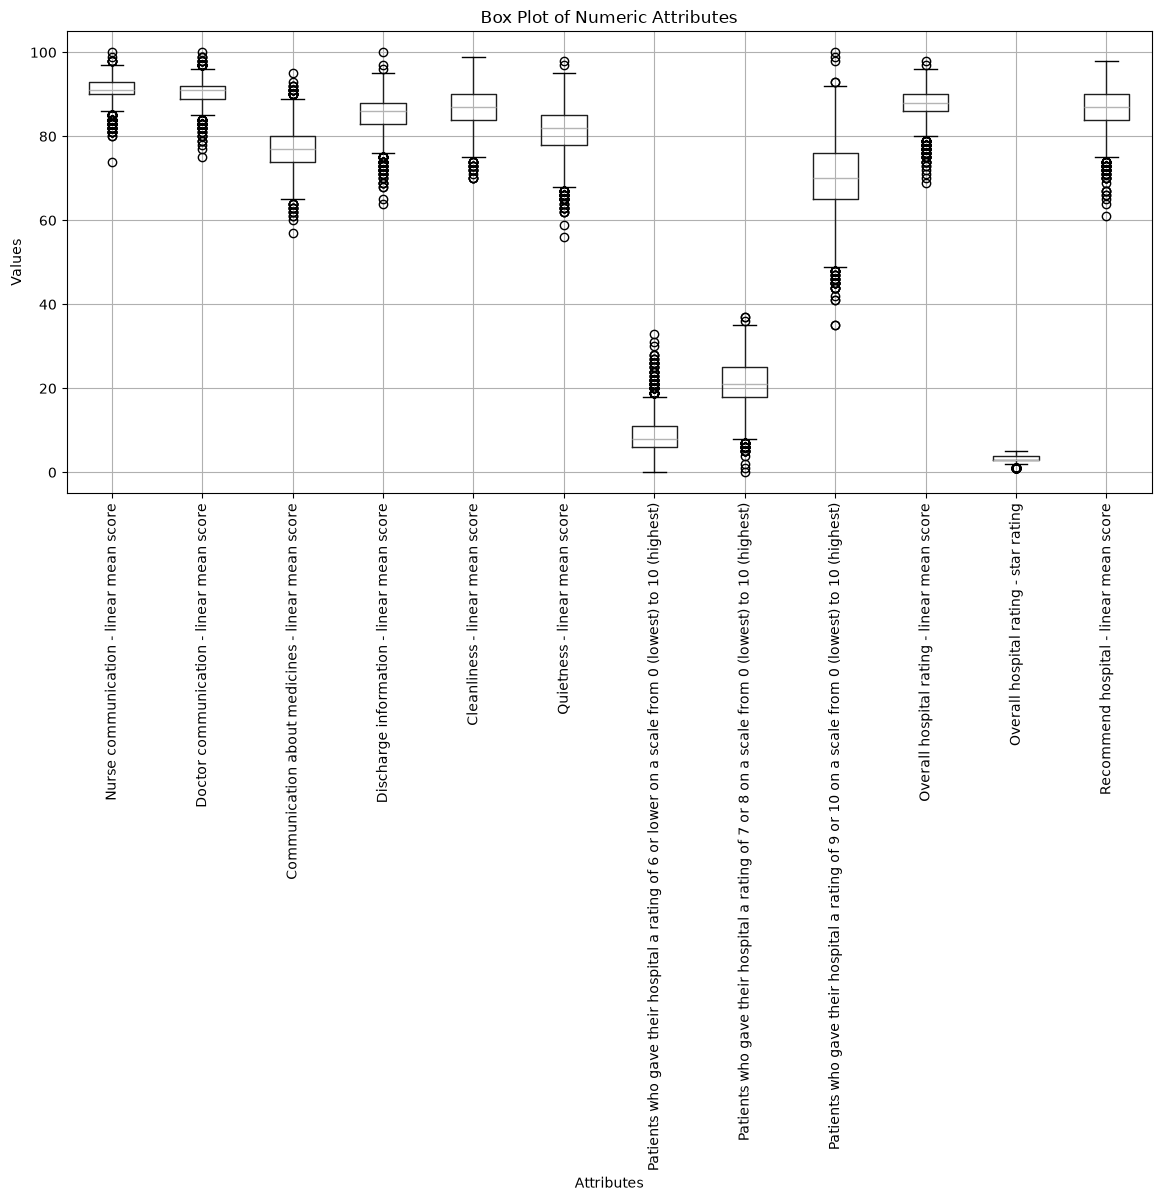

In [12]:
import matplotlib.pyplot as plt

# Remove the completed surveys column from the plot
plot_columns = [col for col in numeric_columns
                if col != "Number of Completed Surveys"]

plt.figure(figsize=(14, 6))

df[plot_columns].boxplot(rot=90)

plt.title("Box Plot of Numeric Attributes")
plt.xlabel("Attributes")
plt.ylabel("Values")
plt.tight_layout()

plt.savefig("all_numeric_attributes_boxplot.png", dpi=300)
plt.show()
plt.close()

In [13]:
# IQR

outlier_summary = {}

for col in numeric_columns:
    q1 = df[col].quantile(.25)
    q3 = df[col].quantile(.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    outlier_summary[col] = len(outliers)

outlier_df = pd.DataFrame.from_dict(
    outlier_summary,
    orient="index",
    columns=["Outlier_Count"]
)

print(outlier_df)

outlier_df.to_csv("outlier_summary.csv")

                                                    Outlier_Count
Nurse communication - linear mean score                        87
Doctor communication - linear mean score                       91
Communication about medicines - linear mean score              39
Discharge information - linear mean score                      64
Cleanliness - linear mean score                                21
Quietness - linear mean score                                  50
Patients who gave their hospital a rating of 6 ...             80
Patients who gave their hospital a rating of 7 ...             37
Patients who gave their hospital a rating of 9 ...             40
Overall hospital rating - linear mean score                    69
Overall hospital rating - star rating                          67
Recommend hospital - linear mean score                         53
Number of Completed Surveys                                   282


In [3]:
import sys
print(sys.executable)

!{sys.executable} -m pip install scikit-learn

c:\Repos\capstone\.venv\Scripts\python.exe
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.29.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.3-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/8.4 MB 3.8 MB/s eta 0:00:02
   ---------- ----------------------------- 2.1/8.4 MB 4.4 MB/s eta 0:00:02
   --------------- ------------------------ 3.1/8.4 MB 4.7 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.4 MB 5.1 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.4 MB 6.2 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 6.9 MB/s  0:00:01
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.3-py3-none-any.whl (


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, RocCurveDisplay,
                             ConfusionMatrixDisplay, classification_report)
from sklearn.inspection import permutation_importance

DATA = Path("HCAHPS_transposed_cleaned.csv")
OUT = Path(".")
RANDOM_STATE = 42

df = pd.read_csv(DATA)
target_col = 'Overall hospital rating - star rating'
df = df.dropna(subset=[target_col]).copy()
df['High_Rating'] = (df[target_col] >= 4).astype(int)

numeric_features = [
    'Nurse communication - linear mean score',
    'Doctor communication - linear mean score',
    'Communication about medicines - linear mean score',
    'Discharge information - linear mean score',
    'Cleanliness - linear mean score',
    'Quietness - linear mean score',
    'Recommend hospital - linear mean score',
    'Number of Completed Surveys',
    'Survey Response Rate Percent',
]
categorical_features = ['State']
features = numeric_features + categorical_features
X = df[features].copy()
y = df['High_Rating']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocess = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', cat_pipe, categorical_features),
])

models = {
    'Dummy baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': LogisticRegression(max_iter=3000, class_weight='balanced', random_state=RANDOM_STATE),
    'Random forest': RandomForestClassifier(n_estimators=500, min_samples_leaf=3, class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient boosting': GradientBoostingClassifier(n_estimators=200, learning_rate=0.04, max_depth=2, random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
fitted = {}
for name, model in models.items():
    pipe = Pipeline([('preprocess', preprocess), ('model', model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring=['accuracy','precision','recall','f1','roc_auc'], n_jobs=-1)
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:,1]
    rows.append({
        'Model': name,
        'CV ROC-AUC mean': scores['test_roc_auc'].mean(),
        'CV ROC-AUC std': scores['test_roc_auc'].std(),
        'CV F1 mean': scores['test_f1'].mean(),
        'Test accuracy': accuracy_score(y_test,pred),
        'Test precision': precision_score(y_test,pred,zero_division=0),
        'Test recall': recall_score(y_test,pred,zero_division=0),
        'Test F1': f1_score(y_test,pred,zero_division=0),
        'Test ROC-AUC': roc_auc_score(y_test,prob),
    })
metrics = pd.DataFrame(rows).sort_values('CV ROC-AUC mean', ascending=False)
metrics.to_csv(OUT/'hcahps_model_metrics.csv', index=False)
best_name = metrics.iloc[0]['Model']
best = fitted[best_name]
best_pred = best.predict(X_test)
best_prob = best.predict_proba(X_test)[:,1]

# Plots
fig, ax = plt.subplots(figsize=(6,5))
for name, pipe in fitted.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax, name=name)
ax.set_title('ROC curves on held-out test set')
fig.tight_layout(); fig.savefig(OUT/'hcahps_roc_curves.png', dpi=180); plt.close(fig)

fig, ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(confusion_matrix(y_test,best_pred), display_labels=['1-3 stars','4-5 stars']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Confusion matrix: {best_name}')
fig.tight_layout(); fig.savefig(OUT/'hcahps_confusion_matrix.png', dpi=180); plt.close(fig)

perm = permutation_importance(best, X_test, y_test, scoring='roc_auc', n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({'Feature':features,'Importance mean':perm.importances_mean,'Importance std':perm.importances_std}).sort_values('Importance mean',ascending=False)
importance.to_csv(OUT/'hcahps_feature_importance.csv',index=False)
fig, ax = plt.subplots(figsize=(8,5))
plotimp=importance.sort_values('Importance mean')
ax.barh(plotimp['Feature'],plotimp['Importance mean'],xerr=plotimp['Importance std'])
ax.set_xlabel('Decrease in test ROC-AUC after permutation')
ax.set_title(f'Permutation importance: {best_name}')
fig.tight_layout(); fig.savefig(OUT/'hcahps_feature_importance.png', dpi=180, bbox_inches='tight'); plt.close(fig)

summary = {
 'rows': int(len(df)), 'features': len(features), 'positive_count': int(y.sum()),
 'positive_rate': float(y.mean()), 'train_rows': int(len(X_train)), 'test_rows': int(len(X_test)),
 'best_model': best_name, 'best_test_confusion_matrix': confusion_matrix(y_test,best_pred).tolist(),
 'classification_report': classification_report(y_test,best_pred,output_dict=True),
 'excluded_leakage_fields': [target_col, 'Overall hospital rating - linear mean score',
   'Summary star rating','Recommend hospital - linear mean score','Recommend hospital - star rating',
   'Patients who gave their hospital a rating of 6 or lower on a scale from 0 (lowest) to 10 (highest)',
   'Patients who gave their hospital a rating of 7 or 8 on a scale from 0 (lowest) to 10 (highest)',
   'Patients who gave their hospital a rating of 9 or 10 on a scale from 0 (lowest) to 10 (highest)']
}
(OUT/'hcahps_model_summary.json').write_text(json.dumps(summary,indent=2))
print(metrics.to_string(index=False))
print('\nSUMMARY',json.dumps(summary,indent=2))
print('\nIMPORTANCE\n',importance.to_string(index=False))


              Model  CV ROC-AUC mean  CV ROC-AUC std  CV F1 mean  Test accuracy  Test precision  Test recall  Test F1  Test ROC-AUC
Logistic regression         0.984105        0.003987    0.916789       0.918367        0.901695     0.920415 0.910959      0.978234
  Gradient boosting         0.982621        0.004777    0.917496       0.918367        0.912892     0.906574 0.909722      0.978443
      Random forest         0.981448        0.005246    0.913047       0.919937        0.902027     0.923875 0.912821      0.977668
     Dummy baseline         0.500000        0.000000    0.000000       0.546311        0.000000     0.000000 0.000000      0.500000

SUMMARY {
  "rows": 3183,
  "features": 10,
  "positive_count": 1444,
  "positive_rate": 0.45366006911718504,
  "train_rows": 2546,
  "test_rows": 637,
  "best_model": "Logistic regression",
  "best_test_confusion_matrix": [
    [
      319,
      29
    ],
    [
      23,
      266
    ]
  ],
  "classification_report": {
    "0": {
    